# Figure 3: Characterization of TF-specific and shared changes in chromatin accessibility
### Loading 60 TF multiome dataset
The following processed dataset:

`atac-rna.preprocessed-s4.signac.rds`

corresponds to:

`GSE353547_Screen60TF_Multiome_mESC_processed_signac.rds`

In [1]:
source("./load_packages.R")

In [2]:
obj <- readRDS("../data/atac-rna.preprocessed-s4.signac.rds")

targets <- sort(unique(obj@meta.data$target[obj@meta.data$target != "" & 
                                             obj@meta.data$target != "NTC" & 
                                             !grepl("_", obj@meta.data$target)]))

### Useful functions
Function for running lochNESS on target cells

In [3]:
target_lochNESS <- function(obj, tf) {
    safe_column_scale = function(bmat, scale_vector) {
      bmat@x <- bmat@x / rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    safe_column_multiply = function(bmat, scale_vector) {
      bmat@x <- bmat@x * rep.int(scale_vector, diff(bmat@p))
      return(bmat)
    }
    kadj = round(0.5 * sqrt(ncol(obj)))

    # adding a "genotype" column that is "KO" for cbcs assigned e.g. a Cdx2 gRNA,
    # and "WT" for all other cells
    if (tf == "NTC") {
        obj@meta.data$genotype <- ifelse(obj@meta.data$target == "NTC", "KO", "WT")
    } else {
        obj@meta.data$genotype <- ifelse(grepl(paste0('(^|_)', tf, '(_|$)'), obj@meta.data$target) == TRUE, "KO", "WT")
    }

    # MT scores
    mt_counts = as.data.frame(table(obj$genotype))
    mutant_mask = ifelse(obj@meta.data$genotype=="WT", 0, 1)
    mutant_neighbors = Matrix::rowSums(safe_column_multiply(obj@graphs$tf.all.peaks_nn, mutant_mask))
    pca_mutant_score = (mutant_neighbors / kadj) / (1 - mt_counts$Freq[mt_counts$Var1=='WT'] / length(mutant_neighbors)) - 1

    # plotting
    mutant_score = pca_mutant_score
    df_umap = as.data.frame(obj[['TFallumap']]@cell.embeddings)

    df_umap$raw_mt_score = mutant_score

    bg1 = df_umap[obj$genotype=="WT",]
    dt1 = df_umap[obj$genotype!="WT",]
    
    df_umap$genotype <- obj@meta.data$genotype[match(rownames(df_umap), rownames(obj@meta.data))]
    df_umap
}


### Figure 3A-D
##### Heatmap of DG sites accessibility across TFs.

##### *Note:*
The per-TF pseudobulk differential accessibility results read in below (`../data/pseudobulk/*.rds`) were generated with `TF-pseudobulk-DESeq2.R` (TF gRNA cells vs NTC) and `NTC-pseudobulk-DESeq2.R` (NTC-matched nulls used to set the FDR cutoff). These files are not included in the repository, so the cells that load them are shown for documentation; to regenerate them, run those scripts on the processed object from GEO (GSE353547). The list of DG and DL sites for each TF is in Table S2. The log2FC matrix computed from these results (`fc_out_raw.csv`) is included, so the heatmap can be regenerated starting from the "Read in the fold-change matrix" step.

Defining a function to load in the DG / DL sites for each TF and apply a FDR cutoff to call significance:

In [4]:
load_da <- function(tf) {
    da_df <- readRDS(paste0("../data/pseudobulk/",tf,".lochNESS-1.dds.tf-all-peaks.rds"))

    cutoffs <- c()
    for (seed in 1:5) {

        background_df <- readRDS(paste0("../data/pseudobulk/NTC-matched.seed-",seed,".",tf,".lochNESS-1.dds.tf-all-peaks.rds"))

        alpha <- 0.05
        lfc_cut <- 1

        # Pre-filter and sort once
        da_mask <- !is.na(da_df$padj) & !is.na(da_df$log2FoldChange) & abs(da_df$log2FoldChange) >= lfc_cut
        bg_mask <- !is.na(background_df$padj) & !is.na(background_df$log2FoldChange) & abs(background_df$log2FoldChange) >= lfc_cut

        da_p <- sort(da_df$padj[da_mask])
        bg_p <- sort(background_df$padj[bg_mask])

        if (length(da_p) == 0) {
          cutoff <- NA_real_
        } else {
          # Evaluate only at DA thresholds
          t <- da_p
          da_pass <- seq_along(t)                 # cumulative DA counts
          bg_pass <- findInterval(t, bg_p)        # cumulative BG counts at same t
          fdr_emp <- bg_pass / da_pass

          ok <- which(fdr_emp <= alpha)
          cutoff <- if (length(ok)) max(t[ok]) else NA_real_
        }

        cutoffs <- c(cutoffs,cutoff)

        }
    
    cut_star <- mean(cutoffs, na.rm = TRUE)
    if (!is.finite(cut_star)) cut_star <- 1  # or another sensible default

    da_df$significance <- ifelse(da_df$padj < cut_star & da_df$log2FoldChange >= 1,"DA",
                          ifelse(da_df$padj <cut_star & da_df$log2FoldChange <= -1,"DL","ns"))

    da_df
}

Reading in the DESeq2 metrics (p-value, log2FC relative to NTC, etc.) for every peak in the dataset for all TFs, and adding to a single dataframe:

In [5]:
all.sites <- as.data.frame(matrix(ncol=0,nrow=0))

for (tf in targets) {
    message(tf)
    da <- load_da(tf)
    da$target <- tf
    da$site <- rownames(da)
    rownames(da) <- paste0(tf,":",da$site)
    all.sites <- rbind(all.sites,da)
    
}

Alx4

Cdx2

Dlx1

Dlx3

Ebf3

Elf5

Esr2

Esrrb

Etv2

Evx2

Foxc1

Foxf1

Foxp1

Foxq1

Gata1

Gata5

Gata6

Glis1

Grhl1

Hes7

Hmx1

Hmx2

Hnf1b

Hoxb5

Klf14

Lbx1

Lhx4

Lhx6

Lmx1a

Lmx1b

Maf

Meox1

Myb

Neurod1

Neurog1

Nfe2

Nfia

Noto

Npas4

Nr3c2

Nrf1

Onecut2

Ovol1

Pax3

Pax7

Pgr

Pou2f2

Pou3f2

Rarb

Runx1

Sox10

Sox5

Sox7

Stat5a

Tbx1

Tbx20

Tbx4

Twist2

Vsx2

Zeb2



Getting a vector list of all unique differentially gained sites:

In [6]:
all.da.sites <- unique(all.sites[all.sites$significance == "DA",]$site)

Getting a subsetted dataframe that just has the differentially gained sites:

In [7]:
all.da <- all.sites[all.sites$significance == "DA",]

Creating a 60 by 60 matrix that has the average fold-change in accessiblity for each TF's DG sites in each TF's gRNA cells:  

In [8]:
fc_out <- as.data.frame(matrix(ncol=0,nrow=0))
for (tf in targets) {
    message(tf)
    try({
    
    tf_sites <- all.sites[all.sites$target == tf,]
    
    values_ <- c(tf)
    for (subtf in c("non-da",targets)) {
        try({ 
        if (subtf == "non-da") {
            DefaultAssay(obj) <- "tf.all.peaks"
            all.peaks <- rownames(obj)
            subtf.da <- all.peaks[!(all.peaks %in% unique(all.da.sites))]
            
            value_ <- sum(tf_sites[tf_sites$site %in% subtf.da,]$log2FoldChange) / length(subtf.da)
            values_ <- c(values_,value_)  
            
            
        } else {
         
            subtf.da <- all.da[all.da$target == subtf,]$site
            value_ <- sum(tf_sites[tf_sites$site %in% subtf.da,]$log2FoldChange) / length(subtf.da)
            values_ <- c(values_,value_)  
  
        }
        })
        
    }
        
    fc_out <- rbind(fc_out,values_)   
        
    })
}

# fc_out currently a data.frame whose first column is 'tf'
colnames(fc_out) <- c("tf", c("Non-DG sites", targets))
rownames(fc_out) <- fc_out$tf

write.csv(fc_out, "../figure_data/fc_out_raw.csv", row.names = FALSE)

Alx4

Cdx2

Dlx1

Dlx3

Ebf3

Elf5

Esr2

Esrrb

Etv2

Evx2

Foxc1

Foxf1

Foxp1

Foxq1

Gata1

Gata5

Gata6

Glis1

Grhl1

Hes7

Hmx1

Hmx2

Hnf1b

Hoxb5

Klf14

Lbx1

Lhx4

Lhx6

Lmx1a

Lmx1b

Maf

Meox1

Myb

Neurod1

Neurog1

Nfe2

Nfia

Noto

Npas4

Nr3c2

Nrf1

Onecut2

Ovol1

Pax3

Pax7

Pgr

Pou2f2

Pou3f2

Rarb

Runx1

Sox10

Sox5

Sox7

Stat5a

Tbx1

Tbx20

Tbx4

Twist2

Vsx2

Zeb2



Read in the fold-change matrix:

In [9]:
fc_out <- read.csv("../figure_data/fc_out_raw.csv", check.names = FALSE)
rownames(fc_out) <- fc_out$tf

Getting a dataframe with the number of DA sites for each target TF. This will be used both for visualization and for removing TFs from the matrix with fewer than 10 DA sites:

In [10]:
n_da <- as.data.frame(matrix(ncol=0,nrow=0))

for (tf in targets) {
    #message(tf)
    try({
    
    n_sites <- nrow(all.sites[all.sites$target == tf & 
                          all.sites$significance == "DA",])
        
    n_da <- rbind(n_da,c(tf,n_sites))
     })   
    }
        
colnames(n_da) <- c("tf","n_sites")

DefaultAssay(obj) <- "tf.all.peaks"
all.peaks <- rownames(obj)
non.da <- unique(all.peaks[!(all.peaks %in% unique(all.da.sites))])

n_da <- rbind(n_da,c("Non-DG sites",length(non.da)))
n_da$n_sites <- as.numeric(n_da$n_sites)

write.csv(n_da, "../figure_data/n_da_sites.csv", row.names = FALSE)

Read in the above number of DA sites per TF: 

In [11]:
n_da <- read.csv("../figure_data/n_da_sites.csv")

Filtering out TF's that have 10 or fewer DA sites:

In [12]:
DA_whitelist <- n_da[n_da$n_sites >= 10,]$tf

colnames(fc_out) <- c("tf", c("Non-DG sites", targets))
rownames(fc_out) <- fc_out$tf

fc_out <- fc_out[,c("tf",DA_whitelist)]

Hierarchical clustering of the fold-change matrix:

In [13]:
# 1) Keep TF labels, drop text col, coerce to numeric matrix
mat <- as.matrix(fc_out[, -1, drop = FALSE])
mode(mat) <- "numeric"   # ensures numeric, coercing any leftover types

# 2) Replace NaN/NA safely (is.na() catches NaN too)
mat[is.na(mat)] <- 0

# 3) Transpose so rows are ("Non-DA sites", targets) and columns are TFs
mat <- t(mat)

# 4) Drop 'Meox1' row if present
if ("Meox1" %in% rownames(mat)) {
  mat <- mat[rownames(mat) != "Meox1", , drop = FALSE]
}

# 5) Split out non-DA row, then cluster and reorder
non_da <- mat[rownames(mat) %in% "Non-DG sites", , drop = FALSE]
mat2   <- mat[!(rownames(mat) %in% "Non-DG sites"), , drop = FALSE]

# Ward.D2 clustering on rows
hclust_result <- hclust(dist(mat2), method = "ward.D2")
row_order <- hclust_result$order

mat2 <- mat2[row_order, , drop = FALSE]
mat2 <- mat2[, rownames(mat2), drop = FALSE]  # columns follow same order

# 6) Reattach non-DA row on top, restricted to the reordered column set
fc_out <- rbind(non_da[, colnames(mat2), drop = FALSE], mat2)

##### Classfication of pioneer status
Adding TF classifications (e.g. pioneeer vs settler etc.) from Ehsani et al. BMC Bioinformatics 2016 (Table S7):

In [14]:
# Read in the table
classes <- read.csv("../data/Ehsani-et-al_BMC-Bioinformatics_2016_TF-classifications.csv",
                            sep=",",
                            header=TRUE)

# Set missing values in "chromatin opening type" as no-classifcation
classes$Chromatin.Opening.Type[
    classes$Chromatin.Opening.Type == ""
] <- "No Classification"

# Change chromatin opening type to all uppercase (inconsistent case in file)
classes$Chromatin.Opening.Type <- toupper(classes$Chromatin.Opening.Type)

# Subset to our 60 TFs of interest
classes <- classes[toupper(classes$Approved.symbol) %in% toupper(targets),c("Symbol","Chromatin.Opening.Type")]

Making the plot:

In [15]:
########################################
# HEATMAP of ACCESSIBILITY
########################################
res <- melt(fc_out)
colnames(res) <- c("tf_DA","tf_cells","value")

res$value <- as.numeric(res$value)
res$value <- ifelse(res$value > 3,3,res$value)
options(repr.plot.width=10, repr.plot.height=12, repr.plot.res=100)

da_p <- ggplot(res[res$tf_cells != "Meox1",], aes(x=tf_cells,y=tf_DA,fill=value)) + 
                  geom_tile(color="black") + 

                    scale_fill_gradient2(
                                low = "blue", mid = "white", high = "red",
                                midpoint = 0, na.value = "grey",
                                limits = c(min(res$value, na.rm=TRUE), 2),
                                oob = scales::squish,
                                labels = function(x) {
                                  # Replace the top tick with ≥2
                                  lab <- as.character(x)
                                  lab[x == max(x)] <- "≥2"
                                  lab
                                }
                              ) +

                  theme(text = element_text(size = 8),
                        axis.text.x = element_text(angle = 45, hjust = 1),
                        legend.position="left") + xlab("gRNA cells") + 
                  ylab("Differentially gained sites") + 
                  labs(fill = bquote(log[2]*.("FC"))) + 
        annotate("rect",
           xmin = which(levels(res$tf_cells) == "Gata1") - 0.5,
           xmax = which(levels(res$tf_cells) == "Grhl1") + 0.5,
           ymin = which(levels(res$tf_DA) == "Gata1") - 0.5,
           ymax = which(levels(res$tf_DA) == "Grhl1") + 0.5,
           fill = NA, color = "#005687", linewidth = .9)  


########################################
# HEATMAP of # OF SITES
########################################
# Calculate log2 of n_sites
n_da$log2_n_sites <- log10(as.numeric(n_da$n_sites))
n_da$log2_n_sites <- ifelse(n_da$tf == "Non-DG sites",NA,n_da$log2_n_sites)


n_da <- n_da[n_da$n_sites >= 10,]

rownames(n_da) <- n_da$tf
n_da <- n_da[rownames(fc_out),]
n_da$tf <-  factor(n_da$tf, levels = rownames(n_da))

options(repr.plot.width=1.5, repr.plot.height=12, repr.plot.res=100)
# Plot heatmap
n <- ggplot(n_da[n_da$tf != "Meox1",], aes(x = 1, y = tf, fill = log2_n_sites)) +
      geom_tile(color="black") +
      #scale_fill_gradient(low = "white", high = "#a4f5a7", name = "log2(n_sites)") +
      geom_text(aes(label = n_sites), vjust = .51,size=6/.pt) +
      theme_minimal() +
      theme(axis.text.y = element_text(size = 8),legend.position="none") +
      labs(x = NULL, y = NULL) + xlab("") +
      scale_fill_gradient2(low = "white", mid = "#e0809e", high = "grey",
                                       midpoint = n_da[n_da$tf == "Cdx2",]$log2_n_sites, 
                                       #midpoint = 0, 
                                       na.value = "lightgrey")


n <- n + scale_x_continuous(breaks = 1, labels = "   # sites") +
  theme(text = element_text(size = 8),axis.text.x = element_text(angle = 45, hjust = 1)) + 
  theme(axis.text.y = element_blank(),legend.position="none")



########################################
# HEATMAP of TF CLASSIFICATION
########################################
classes$Symbol <- paste0(
  substr(classes$Symbol, 1, 1),
  tolower(substr(classes$Symbol, 2, nchar(classes$Symbol)))
)

class_df <- classes[classes$Symbol %in% rownames(fc_out),
                    c("Symbol", "Chromatin.Opening.Type")]

missing_tfs <- setdiff(rownames(fc_out), class_df$Symbol)

if (length(missing_tfs) > 0) {
  class_df <- rbind(
    class_df,
    data.frame(
      Symbol = missing_tfs,
      Chromatin.Opening.Type = "NO CLASSIFICATION"
    )
  )
}

rownames(class_df) <- class_df$Symbol
class_df <- class_df[rownames(fc_out), ]

class_df$tf <- factor(class_df$Symbol, levels = rownames(fc_out))
class_df$Chromatin.Opening.Type <- factor(class_df$Chromatin.Opening.Type)


class_cols <- c(
  "SETTLER" = "#a2e1c2",
  "PIONEER" = "#2a97f8",
  "MIGRANT" = "#984ea3",
  "NEGATIVE MIGRANT" = "#B33F62",
  "POSITIVE MIGRANT" = "#c99400",
  "NO CLASSIFICATION" = "lightgrey"
)

class_p <- ggplot(class_df[class_df$tf != "Meox1", ],
                  aes(x = 1, y = tf, fill = Chromatin.Opening.Type)) +
  geom_tile(color = "black") +
  scale_fill_manual(values = class_cols, drop = FALSE) +
  scale_x_continuous(breaks = 1, labels = "  TF class") +
  theme_minimal() +
  theme(
    text = element_text(size = 8),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.text.y = element_blank(),
    legend.position = "right"
  ) +
  labs(x = NULL, y = NULL, fill = "TF class")

##### Motif enrichment in DG sites with monaLisa
Performing motif enrichment in DG sites using monaLisa so we can add it as an additional heatmap. First defining functions to perform the enrichment:

In [16]:
compare_da_genomeBG <- function(sites, genome.oversample = 2, rng.seed = 42, pwm.subset = NULL) {
    library(JASPAR2020)
    library(TFBSTools)
    library(BSgenome.Mmusculus.UCSC.mm10)
    library(monaLisa)
    library(BiocParallel)

    # Get all vertebrate PWMs
    pwms <- getMatrixSet(JASPAR2020,
                         opts = list(matrixtype = "PWM",
                                     tax_group = "vertebrates"))

    # Optionally subset PWM list
    if (!is.null(pwm.subset)) {
        pwms <- pwms[pwm.subset]
    }

    # Convert input to GRanges and fix width
    sites_gr <- fix_gr_width(sites_granges(sites), 500)

    # Extract DNA sequences
    seqs <- getSeq(BSgenome.Mmusculus.UCSC.mm10, sites_gr)

    # Run enrichment with genome-sampled GC-matched background
    se <- calcBinnedMotifEnrR(seqs = seqs,
                           pwmL = pwms,
                           background = "genome",
                           genome = BSgenome.Mmusculus.UCSC.mm10,
                           genome.regions = NULL, # sample from full genome
                           genome.oversample = 2, 
                           BPPARAM = BiocParallel::SerialParam(RNGseed = 42),
                           verbose = TRUE)

    return(se)
}

fix_gr_width <- function(da_gr, fixed_width) {
    # Calculate the summit (midpoint) for da_gr
    da_gr$summit <- (start(da_gr) + end(da_gr)) / 2

    # Calculate the new start and end positions for resized_gr
    new_start <- start(da_gr) + (width(da_gr) - fixed_width) / 2
    new_end <- new_start + fixed_width

    # Create a new GRanges object with the resized ranges
    resized_gr <- GRanges(
      seqnames = seqnames(da_gr),
      ranges = IRanges(start = new_start, end = new_end),
      strand = strand(da_gr)
    )

    # Recalculate the summit for resized_gr using the resized start and end values
    resized_gr$summit <- (start(resized_gr) + end(resized_gr)) / 2

    resized_gr
    }

sites_granges <- function(sites) {

    # Split each element in the vector by '-' and create a data frame
    site_df <- data.frame(do.call(rbind, strsplit(sites, "-")))

    # Rename the columns
    colnames(site_df) <- c("seqnames", "start", "end")

    # Convert "start" and "end" columns to numeric (if needed)
    site_df$start <- as.numeric(site_df$start)
    site_df$end <- as.numeric(site_df$end)
    site_gr <- makeGRangesFromDataFrame(site_df)
    site_gr

}


se_to_df <- function(se) {
    # Build dataframe with rownames as motif IDs or motif names
    df <- data.frame(
        motif_id   = rownames(se),
        motif_name = rowData(se)$motif.name,
        log2enr    = assay(se, "log2enr")[, 1],
        negLog10Padj = assay(se, "negLog10Padj")[, 1],
        stringsAsFactors = FALSE
    )

    df
    }



In [17]:
se_out <- as.data.frame(matrix(ncol=0,nrow=0)) 
for (tf in rownames(fc_out[2:nrow(fc_out),])) {
    
     sites <- all.da[all.da$target == tf,]$site
    
     message(paste0(tf,": ",length(sites)))
     se <- suppressWarnings(compare_da_genomeBG(sites))
     se.df <- se_to_df(se)
     se.df$target <- tf
    
     se_out <- rbind(se_out,se.df)
 }

saveRDS(se_out,file="../figure_data/dg-motif-enrichment.monaLisa.rds")

In [18]:
se_out <- readRDS("../figure_data/dg-motif-enrichment.monaLisa.rds")

In [19]:
########################################
# HEATMAP of MOTIF FAMILY ENRICHMENT
########################################
motif_enr <- se_out

motif_enr$motif_family <- gsub("[0-9]+$", "", motif_enr$motif_name)
motif_enr$target_family <- gsub("[0-9]+$", "", motif_enr$target)

motif_enr$log2enr <- as.numeric(motif_enr$log2enr)

motif_enr <- motif_enr[
  toupper(motif_enr$motif_family) == toupper(motif_enr$target_family) &
    motif_enr$negLog10Padj > 2,
]

motif_enr <- motif_enr[order(motif_enr$target, -motif_enr$log2enr), ]

motif_enr <- motif_enr[!duplicated(motif_enr$target), ]

motif_df <- data.frame(tf = rownames(fc_out))
motif_df$log2enr <- motif_enr$log2enr[match(motif_df$tf, motif_enr$target)]
motif_df$motif_name <- motif_enr$motif_name[match(motif_df$tf, motif_enr$target)]
motif_df$negLog10Padj <- motif_enr$negLog10Padj[match(motif_df$tf, motif_enr$target)]

motif_df$tf <- factor(motif_df$tf, levels = rownames(fc_out))

motif_p <- ggplot(motif_df[motif_df$tf != "Meox1", ],
                  aes(x = 1, y = tf, fill = log2enr)) +
  geom_tile(color = "black") +
  scale_fill_gradient2(
    low = "blue", mid = "white", high = "red",
    midpoint = 0,
    na.value = "grey",
    name = "monaLisa FC"
  ) +
  scale_x_continuous(breaks = 1, labels = "monaLisa") +
  theme_minimal() +
  theme(
    text = element_text(size = 8),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.text.y = element_blank(),
    legend.position = "right"
  ) +
  labs(x = NULL, y = NULL)

##### Motif accessibility with chromVAR
*chromVAR_overall_diffMotifs.csv* contains differences in motif accessibility between pseudobulked target-TF gRNA cells and NTC cells, one row per (target TF, motif).

In [20]:
chromvar_res <- read.table("../figure_data/chromVAR_overall_diffMotifs.csv",sep=",",header=TRUE)

########################################
# HEATMAP of TOP FAMILY MOTIF logFC
########################################
motif_df2 <- chromvar_res

motif_df2$motif_family <- gsub("[0-9]+$", "", motif_df2$motif)
motif_df2$target_family <- gsub("[0-9]+$", "", motif_df2$Target)

motif_df2$logFC <- as.numeric(motif_df2$logFC)

motif_df2 <- motif_df2[
  toupper(motif_df2$motif_family) == toupper(motif_df2$target_family) &
    motif_df2$adj.P.Val < 0.05,
]

motif_df2 <- motif_df2[order(motif_df2$Target, -motif_df2$logFC), ]
motif_df2 <- motif_df2[!duplicated(motif_df2$Target), ]

motif_plot_df2 <- data.frame(tf = rownames(fc_out))
motif_plot_df2$logFC <- motif_df2$logFC[match(motif_plot_df2$tf, motif_df2$Target)]
motif_plot_df2$motif <- motif_df2$motif[match(motif_plot_df2$tf, motif_df2$Target)]
motif_plot_df2$adj.P.Val <- motif_df2$adj.P.Val[match(motif_plot_df2$tf, motif_df2$Target)]

motif_plot_df2$tf <- factor(motif_plot_df2$tf, levels = rownames(fc_out))

motif_plot_df2$logFC <- ifelse(motif_plot_df2$logFC > 15,15,motif_plot_df2$logFC)
motif_plot_df2$logFC <- ifelse(motif_plot_df2$logFC < -15,-15,motif_plot_df2$logFC)


motif_p2 <- ggplot(motif_plot_df2[motif_plot_df2$tf != "Meox1", ],
                   aes(x = 1, y = tf, fill = logFC)) +
  geom_tile(color = "black") +
  scale_fill_gradient2(
    low = "blue", mid = "white", high = "red",
    midpoint = 0,
    na.value = "grey",
    name = "chromVAR logFC"
  ) +
  scale_x_continuous(breaks = 1, labels = "chromVAR") +
  theme_minimal() +
  theme(
    text = element_text(size = 8),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.text.y = element_blank(),
    legend.position = "right"
  ) +
  labs(x = NULL, y = NULL)

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <a5>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≥2' in 'mbcsToSbcs': dot substituted for <a5>"


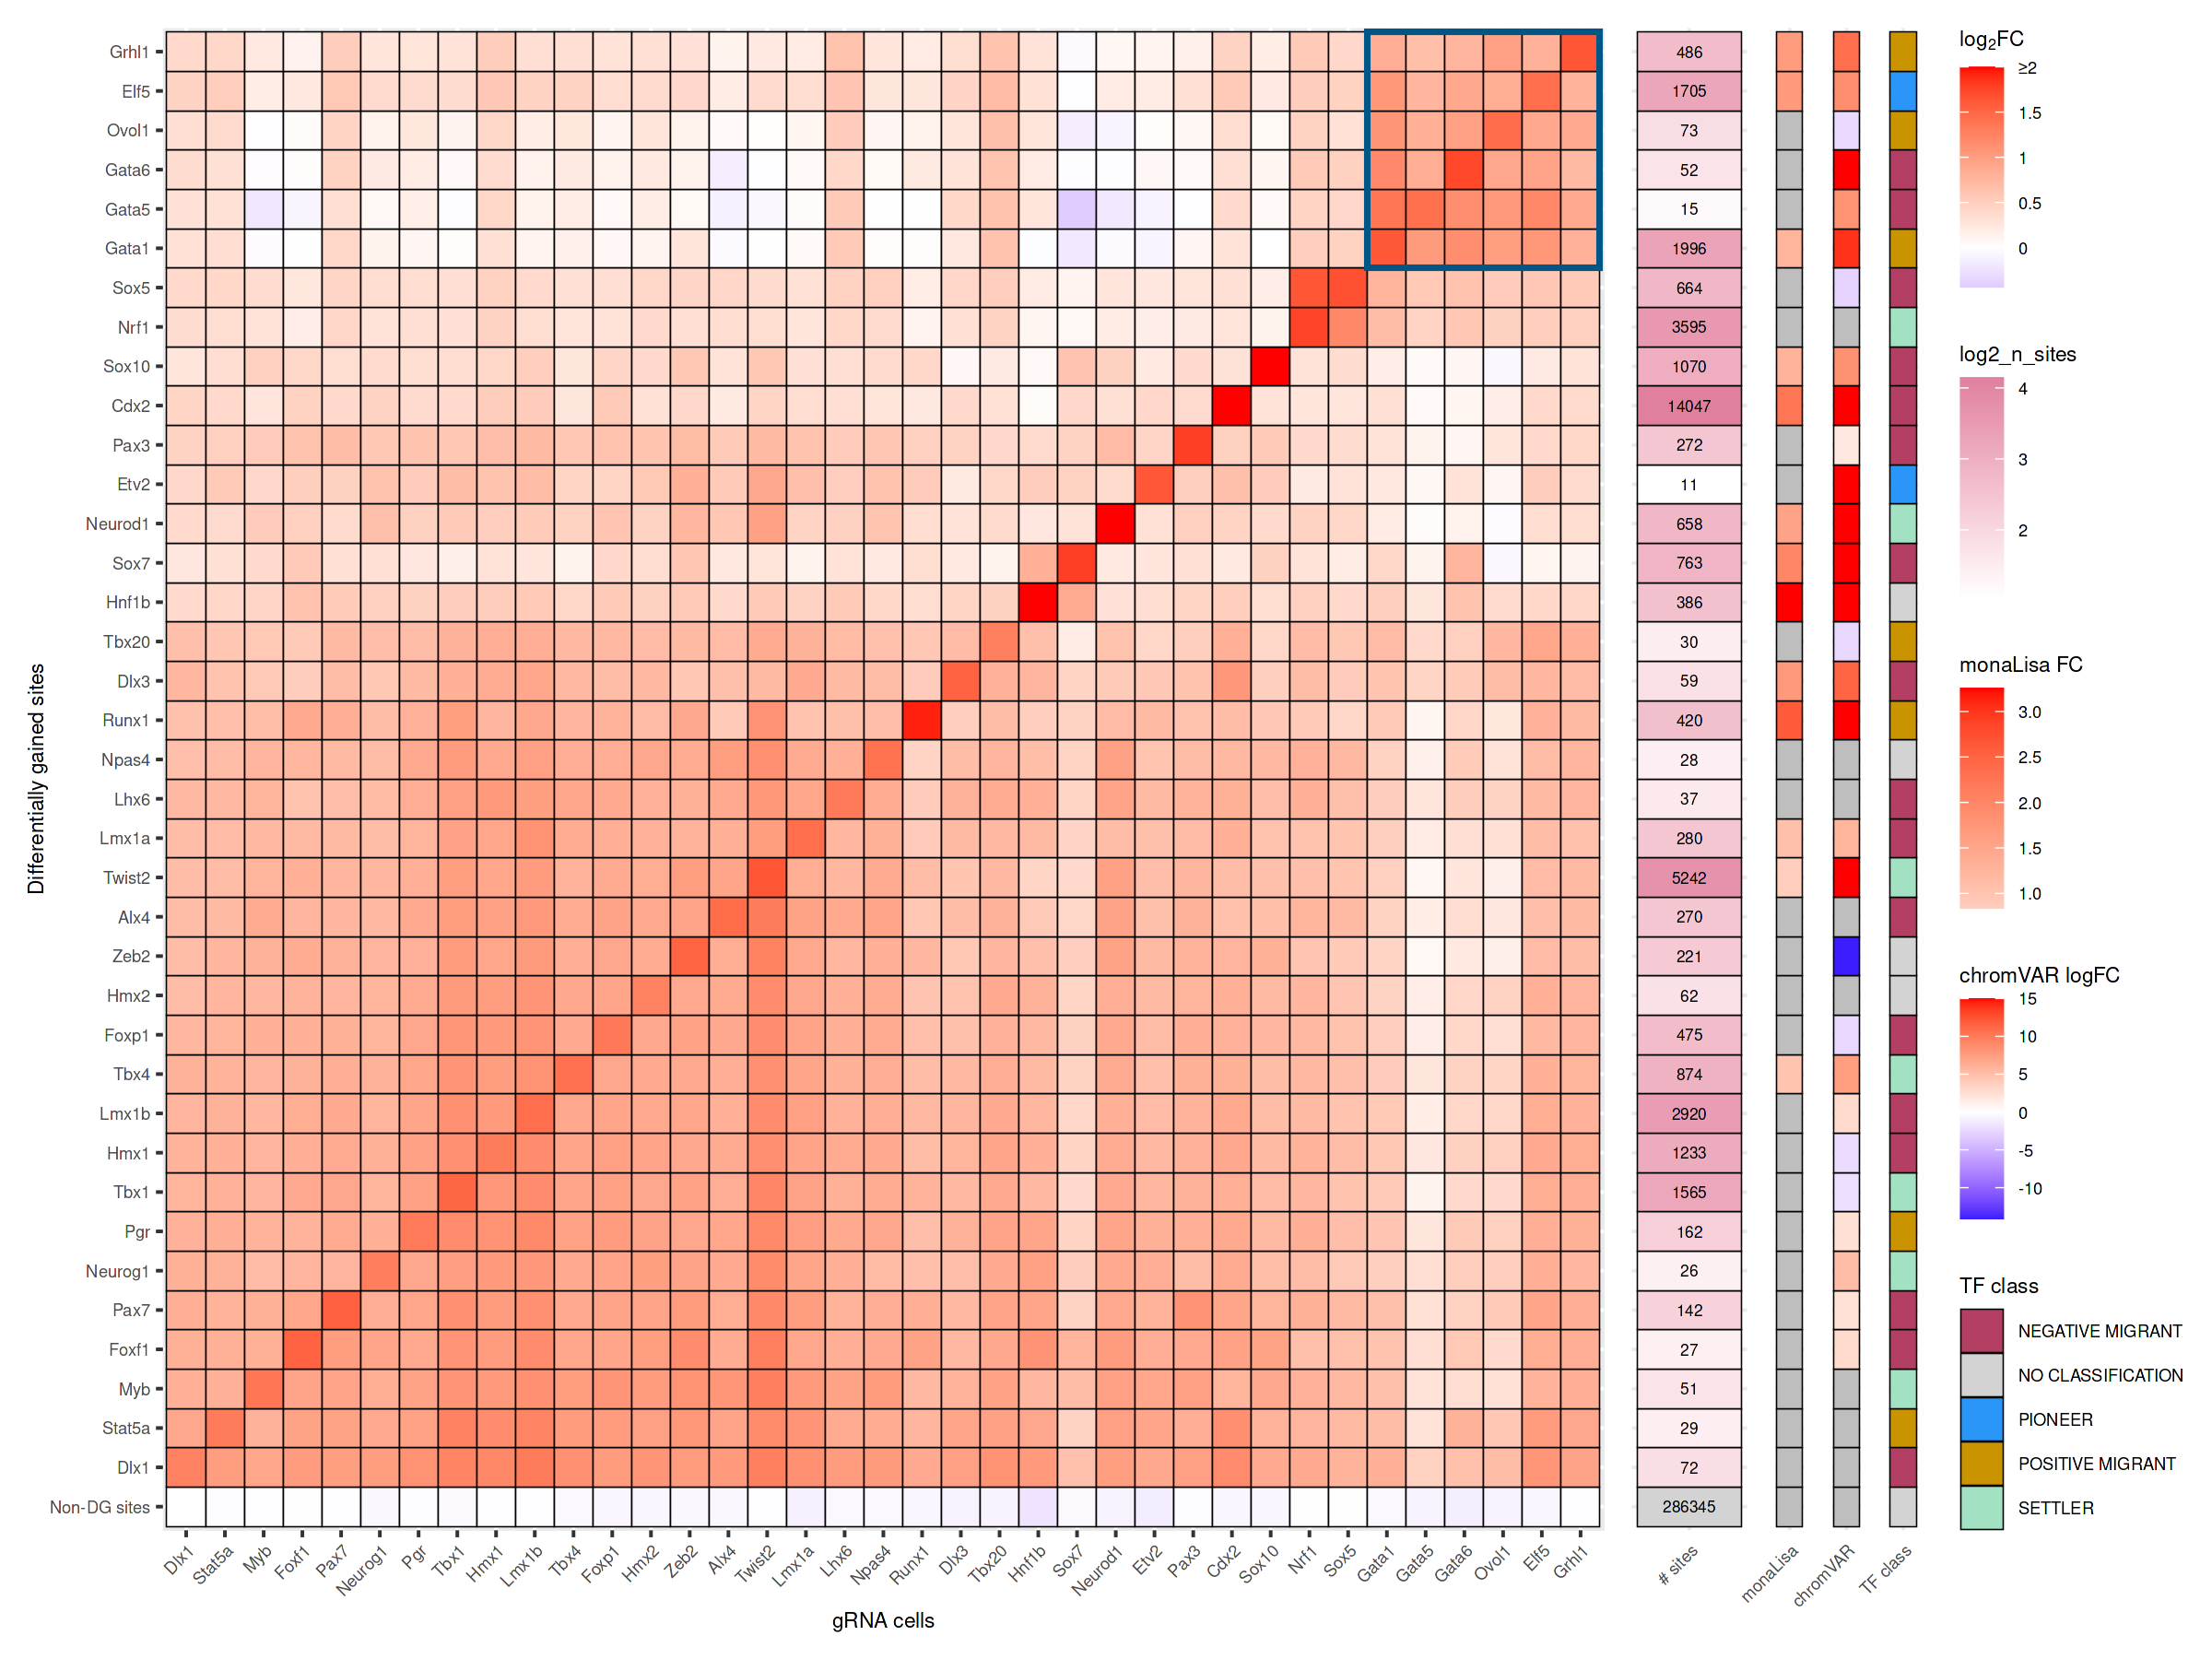

In [21]:
options(repr.plot.width=12, repr.plot.height=9, repr.plot.res=200)

layout <- "
ABCDE
"

da_p + n  + motif_p + motif_p2 + class_p +
  plot_layout(
    design = layout,
    widths = c(1, 0.08, .02, .02,.02),
    guides = "collect"
  ) &
  theme(legend.position = "right")

##### Distributions of the distance to nearest TSS as well as phyloP conservation scores.
First, getting a set of background genomic sequences that are GC matched to the differentially gained sites:

In [22]:
DG <- unique(all.sites[all.sites$significance == "DA",]$site)
DG_gr <- StringToGRanges(DG, sep = c("-", "-"))

W <- round(median(width(DG_gr)))
pool <- tileGenome(seqlengths(BSgenome.Mmusculus.UCSC.mm10), tilewidth = W,
                   cut.last.tile.in.chrom = TRUE)


# 1. Compute GC% for both
get_gc <- function(gr) {
  seqs <- getSeq(BSgenome.Mmusculus.UCSC.mm10, gr)
  letterFrequency(seqs, "GC", as.prob = TRUE)[, 1] * 100
}

DG_df <- data.frame(GC.percent = get_gc(DG_gr), width = width(DG_gr))
pool_df <- data.frame(GC.percent = get_gc(pool), width = width(pool))

# 2. Match
set.seed(42)
matched_idx <- MatchRegionStats(
  meta.feature = pool_df,      # background
  query.feature = DG_df,       # foreground
  features.match = c("GC.percent", "width"),
  n = nrow(DG_df),
  verbose = TRUE
)

# 3. Subset your pool GRanges to get matched regions
matched_idx <- as.numeric(matched_idx)
bg_gr <- pool[matched_idx]

bg_df <- as.data.frame(bg_gr)
bg_df$peak <- paste(bg_df$seqnames,bg_df$start,bg_df$end,sep="-")

DG_gc  <- get_gc(DG_gr)
BG_gc  <- get_gc(bg_gr)

summary(DG_gc)
summary(BG_gc)

mean(DG_gc); sd(DG_gc)
mean(BG_gc); sd(BG_gc)

Matching GC.percent distribution

Matching width distribution



   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  28.23   43.32   46.46   46.55   49.69   68.07 

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   0.00   42.16   44.78   44.69   47.20   61.94 

[1] 46.54627

[1] 4.798514

[1] 44.68596

[1] 3.884989

Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"
Warn

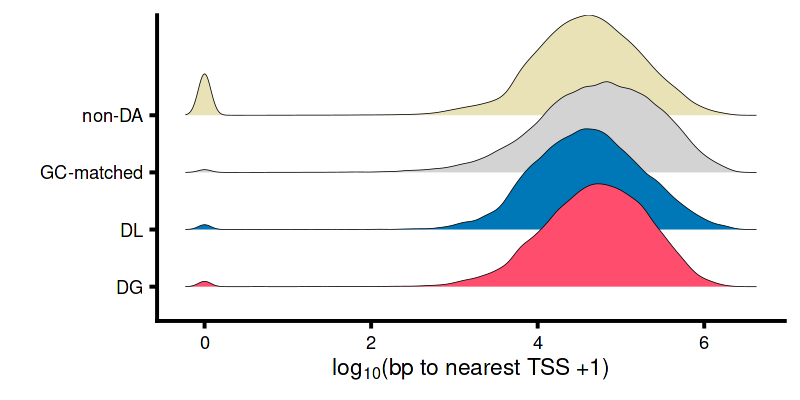

In [23]:
sites_granges <- function(sites) {
    
    # Split each element in the vector by '-' and create a data frame
    site_df <- data.frame(do.call(rbind, strsplit(sites, "-")))

    # Rename the columns
    colnames(site_df) <- c("seqnames", "start", "end")

    # Convert "start" and "end" columns to numeric (if needed)
    site_df$start <- as.numeric(site_df$start)
    site_df$end <- as.numeric(site_df$end)
    site_gr <- makeGRangesFromDataFrame(site_df)
    site_gr
    
}

options(download.file.method = "curl")
suppressMessages(library(EnsDb.Mmusculus.v79))
suppressMessages(library(BSgenome.Mmusculus.UCSC.mm10))

annotation <- GetGRangesFromEnsDb(ensdb = EnsDb.Mmusculus.v79)
seqlevelsStyle(annotation) <- "UCSC"
genome(annotation) <- "mm10"

tss.positions <- GetTSSPositions(annotation, biotypes = "protein_coding")

tss.positions <- as.data.frame(tss.positions)
tss.positions$start <- tss.positions$start -5
tss.positions$end <- tss.positions$end + 5
tss.positions$range <- paste0(tss.positions$seqnames,"-",tss.positions$start,"-",tss.positions$end)

tss_gr <- makeGRangesFromDataFrame(tss.positions,keep.extra.columns=TRUE)


DefaultAssay(obj) <- "tf.all.peaks"
peak_gr <- sites_granges(rownames(obj))

bg_gr <- bg_gr[seqnames(bg_gr) %in% unique(seqnames(peak_gr))]
peak_gr <- c(peak_gr, bg_gr)

distances_gr <- distanceToNearest(peak_gr, tss_gr)


tss_df <- as.data.frame(tss_gr[subjectHits(distances_gr)])
peak_df <- as.data.frame(peak_gr)
distance_df <- as.data.frame(distances_gr)

peak_df$nearestTSS <- tss_df$range
peak_df$nearestGene <- tss_df$gene_name
peak_df$distance <- distance_df$distance
peak_df$peak <- paste(peak_df$seqnames,peak_df$start,peak_df$end,sep="-")

# vector of all unique DG sites, DL sites, and non DA sites
peaks <- unique(all.sites$site)
DG <- unique(all.sites[all.sites$significance == "DA",]$site)
DL <- unique(all.sites[all.sites$significance == "DL" &
                       !(all.sites$site %in% DG),]$site)
non_DA <- peaks[!(peaks %in% unique(c(DG,DL,bg_df$peak)))]


peak_df$sig <- ifelse(peak_df$peak %in% DG,"DG",
               ifelse(peak_df$peak %in% DL,"DL",
               ifelse(peak_df$peak %in% non_DA,"non-DA","GC-matched")))



dist <- ggplot(peak_df,
       aes(x=log10(distance + 1),y=sig,fill=sig)) + 
       geom_density_ridges(linewidth=.1) + 
           theme_classic() +
           theme(text = element_text(size = 8),
                 legend.position="none",
            axis.line = element_line(color = "black"),
            panel.grid = element_blank()) + 
       scale_fill_manual(values=rev(c("#eae2b7ff","lightgrey","#0077b6ff","#ff4d6dff")))+ 
                     xlab(bquote(log[10]*.("(bp to nearest TSS +1)"))) + 
       ylab("")

options(repr.plot.width=4, repr.plot.height=2, repr.plot.res=200)
dist

In [24]:
peak_gr <- sites_granges(rownames(obj))

bg_gr <- bg_gr[seqnames(bg_gr) %in% unique(seqnames(peak_gr))]

sites.gr <- c(peak_gr, bg_gr)

setAnnotationHubOption("MAX_DOWNLOADS", 100L)

# Ensuring GRanges uses UCSC-style seqlevels (chr1, chr2, …)
seqlevelsStyle(sites.gr) <- "UCSC"

# Loading the mm10 conservation tracks
phyloP    <- getGScores("phyloP60way.UCSC.mm10")
phastCons <- getGScores("phastCons60way.UCSC.mm10")

# Scoring sites 
phyloP_gr    <- gscores(phyloP,    sites.gr)      # per-interval scores
phastCons_gr <- gscores(phastCons, sites.gr)

sites.gr$phyloP60    <- mcols(phyloP_gr)[["default"]]
sites.gr$phastCons60 <- mcols(phastCons_gr)[["default"]]

# vector of all unique DG sites, DL sites, and non DA sites
peaks <- unique(all.sites$site)
DG <- unique(all.sites[all.sites$significance == "DA",]$site)
DL <- unique(all.sites[all.sites$significance == "DL" &
                       !(all.sites$site %in% DG),]$site)
non_DA <- peaks[!(peaks %in% unique(c(DG,DL,bg_df$peak)))]

cons.df <- as.data.frame(sites.gr)
cons.df$peak <- paste(cons.df$seqnames,cons.df$start,cons.df$end,sep="-")

loading from cache

loading from cache



In [25]:
cons.df$sig <- ifelse(cons.df$peak %in% DG,"DG",
               ifelse(cons.df$peak %in% DL,"DL",
               ifelse(cons.df$peak %in% non_DA,"non-DA","GC-matched")))

has_cons <- as.data.frame(table(cons.df[is.na(cons.df$phyloP) == FALSE,]$sig))
colnames(has_cons) <- c("sig","n_phyloP")

all_cons <- as.data.frame(table(cons.df$sig))
colnames(all_cons) <- c("sig","n_sites")

all_cons$n_phyloP <- has_cons$n_phyloP[match(all_cons$sig,has_cons$sig)]

all_cons$percent_phyloP <- 100*all_cons$n_phyloP/all_cons$n_sites


b <- ggplot(all_cons, aes(x = percent_phyloP, y = sig,fill=sig)) +
  geom_col(color="black",linewidth=.1) +
           theme_classic() +
           theme(text = element_text(size = 8),
                 legend.position="none",
            axis.line = element_line(color = "black"),
            panel.grid = element_blank()) +
       xlab("% sites w/ phyloP score") +
       ylab("") +
       scale_fill_manual(values=rev(c("#eae2b7ff","lightgrey","#0077b6ff","#ff4d6dff")))

Picking joint bandwidth of 0.076



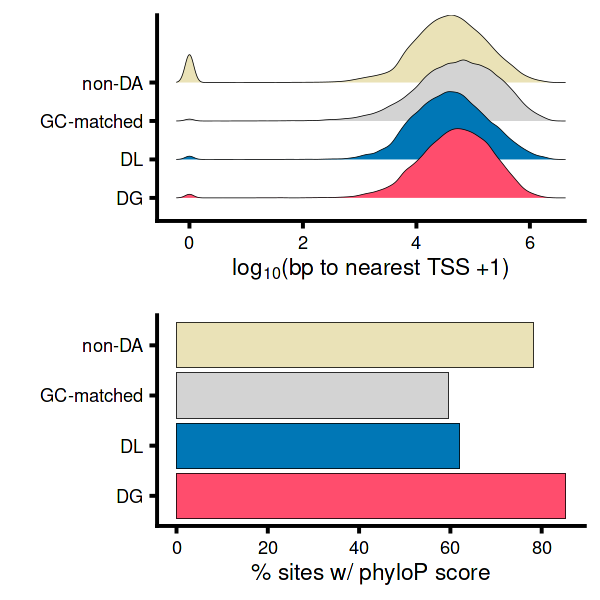

In [26]:
options(repr.plot.width=3, repr.plot.height=3, repr.plot.res=200)
fig3_a_b <- ggarrange(dist,b,ncol=1,nrow=2)
fig3_a_b

##### Overlap of peaks with mouse-embryoid-body (mEB) ATAC panel 
Load pseudobulk ATAC accessibility per embryoid-body cell type from Lalanne et al. (GEO GSE217683) and assign each peak to its most-specific cell type.

In [27]:
library(tidyverse)

url <- "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE217nnn/GSE217683/suppl/GSE217683_scATAC_mEB_d21_pseudobulk_accessibility_per_cluster.txt.gz"

atac <- read_tsv(url)

head(atac)
colnames(atac)

Rows: 252569 Columns: 12
── Column specification ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Delimiter: "\t"
chr  (2): unique_peak_id, chr
dbl (10): start, end, ArchR_peak_score, pluripotent_epiblast, ex_endo_pariet...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


unique_peak_id,chr,start,end,ArchR_peak_score,pluripotent_epiblast,ex_endo_parietal,ex_endo_intermediate_parietal,surface_ectoderm,ex_endo_visceral,mesoderm,neuroectoderm
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
chr1_1,chr1,3035673,3036173,7.86995,2.028328e-05,1.973552e-07,2.095020e-06,2.772848e-06,1.501427e-06,1.104765e-06,4.389083e-06
chr1_2,chr1,3044838,3045338,8.24154,1.104062e-06,7.215138e-06,2.557827e-05,2.770397e-06,4.370514e-05,2.132196e-06,3.545911e-06
chr1_3,chr1,3048286,3048786,3.40252,3.158268e-06,6.259854e-06,2.455464e-05,2.832122e-06,3.280779e-05,2.164666e-06,1.883154e-06
chr1_4,chr1,3062699,3063199,30.95774,1.034997e-04,2.550076e-06,3.538093e-06,1.998795e-06,8.017485e-07,1.935922e-06,6.709107e-06
chr1_5,chr1,3072330,3072830,33.18485,3.178063e-06,9.738526e-05,7.858110e-05,2.297034e-06,8.759596e-06,0.000000e+00,2.546338e-06
chr1_6,chr1,3094470,3094970,6.07381,1.615368e-06,9.688112e-07,3.681769e-06,4.454066e-05,2.920628e-06,7.238712e-06,8.257103e-06


[1] "unique_peak_id"                "chr"                          
 [3] "start"                         "end"                          
 [5] "ArchR_peak_score"              "pluripotent_epiblast"         
 [7] "ex_endo_parietal"              "ex_endo_intermediate_parietal"
 [9] "surface_ectoderm"              "ex_endo_visceral"             
[11] "mesoderm"                      "neuroectoderm"

In [28]:
celltype_cols <- c(
  "pluripotent_epiblast",
  "ex_endo_parietal",
  "ex_endo_intermediate_parietal",
  "surface_ectoderm",
  "ex_endo_visceral",
  "mesoderm",
  "neuroectoderm"
)

n_ <- nrow(atac)

atac$max_celltype <- NA_character_
atac$max_accessibility <- NA_real_
atac$mean_other <- NA_real_
atac$specificity_log2FC <- NA_real_

pb <- txtProgressBar(min = 0, max = n_, style = 3)

for (i in seq_len(n_)) {
    vals <- as.numeric(atac[i, celltype_cols])
    max_idx <- which.max(vals)
    atac$max_celltype[i] <- celltype_cols[max_idx]
    atac$max_accessibility[i] <- vals[max_idx]
    atac$mean_other[i] <- mean(vals[-max_idx])
    atac$specificity_log2FC[i] <- log2(
        (vals[max_idx] + 1e-10) /
        (atac$mean_other[i] + 1e-10)
    )
    if (i %% 1000 == 0 || i == n_) {
        setTxtProgressBar(pb, i)
    }
}

close(pb)

  |======================================================================| 100%


In [29]:
atac$EB_category <- ifelse(
    atac$specificity_log2FC < 3,
    "non_specific",
    atac$max_celltype
)
table(atac$EB_category)


ex_endo_intermediate_parietal              ex_endo_parietal 
                          325                          4392 
             ex_endo_visceral                      mesoderm 
                         6482                          5418 
                neuroectoderm                  non_specific 
                         5950                        206607 
         pluripotent_epiblast              surface_ectoderm 
                        18128                          5267 

In [30]:
library(GenomicRanges)

## mEB ATAC GRanges
meb_gr <- GRanges(
    seqnames = atac$chr,
    ranges = IRanges(start = atac$start, end = atac$end)
)

## peak_df GRanges
query_gr <- GRanges(
    seqnames = peak_df$seqnames,
    ranges = IRanges(start = peak_df$start, end = peak_df$end),
    sig = peak_df$sig,
    peak = peak_df$peak
)

## annotate each query peak as overlapping mEB ATAC or not
query_gr$overlap_mEB <- countOverlaps(query_gr, meb_gr) > 0

peak_df$overlap_mEB <- query_gr$overlap_mEB

In [31]:
atac$EB_category <- ifelse(
    atac$specificity_log2FC < 3,
    "non_specific",
    atac$max_celltype
)

library(GenomicRanges)

meb_gr <- GRanges(
    seqnames = atac$chr,
    ranges = IRanges(start = atac$start, end = atac$end),
    EB_category = atac$EB_category
)

query_gr <- GRanges(
    seqnames = peak_df$seqnames,
    ranges = IRanges(start = peak_df$start, end = peak_df$end),
    sig = peak_df$sig,
    peak = peak_df$peak
)

hits <- findOverlaps(query_gr, meb_gr)

overlap_df <- data.frame(
    peak = query_gr$peak[queryHits(hits)],
    sig = query_gr$sig[queryHits(hits)],
    EB_category = meb_gr$EB_category[subjectHits(hits)]
)

test_category_enrichment <- function(
    peak_df,
    overlap_df,
    peak_group,
    background_group,
    eb_category
) {

    overlap_peaks <- unique(
        overlap_df$peak[
            overlap_df$EB_category == eb_category
        ]
    )

    sub <- peak_df[peak_df$sig %in% c(peak_group, background_group), ]

    sub$overlap <- sub$peak %in% overlap_peaks

    group1_overlap <- sum(sub$sig == peak_group & sub$overlap)
    group1_total <- sum(sub$sig == peak_group)

    group2_overlap <- sum(sub$sig == background_group & sub$overlap)
    group2_total <- sum(sub$sig == background_group)

    m <- sum(sub$overlap)
    n_2 <- sum(!sub$overlap)

    p <- phyper(
        q = group1_overlap - 1,
        m = m,
        n = n_2,
        k = group1_total,
        lower.tail = FALSE
    )

    group1_frac <- group1_overlap / group1_total
    group2_frac <- group2_overlap / group2_total

    data.frame(
        EB_category = eb_category,
        group1 = peak_group,
        group2 = background_group,
        group1_overlap = group1_overlap,
        group1_total = group1_total,
        group1_frac = group1_frac,
        group2_overlap = group2_overlap,
        group2_total = group2_total,
        group2_frac = group2_frac,
        fold_enrichment = group1_frac / group2_frac,
        p_value = p
    )
}



In [32]:
eb_categories <- unique(atac$EB_category)

results <- do.call(
    rbind,
    lapply(eb_categories, function(cat) {

        rbind(
            test_category_enrichment(peak_df, overlap_df, "DG", "non-DA", cat),
            test_category_enrichment(peak_df, overlap_df, "DL", "non-DA", cat),
            test_category_enrichment(peak_df, overlap_df, "GC-matched", "non-DA", cat),

            test_category_enrichment(peak_df, overlap_df, "DG", "GC-matched", cat),
            test_category_enrichment(peak_df, overlap_df, "DL", "GC-matched", cat),
            test_category_enrichment(peak_df, overlap_df, "non-DA", "GC-matched", cat)
        )
    })
)

results$p_adj <- p.adjust(results$p_value, method = "BH")


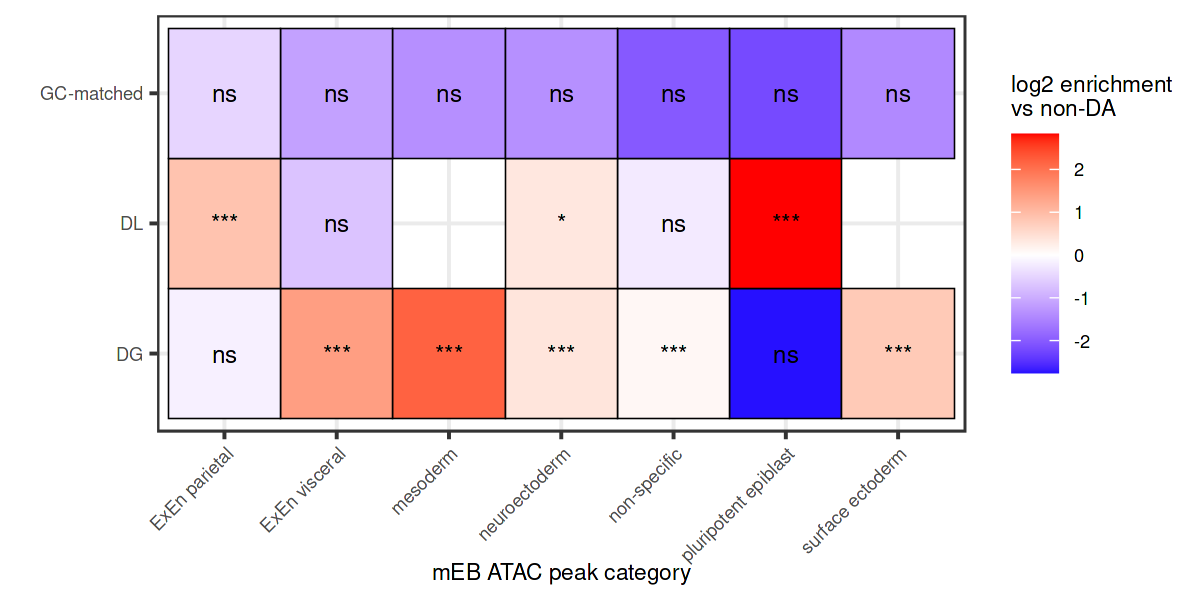

In [33]:
results_plot <- results[
    results$group2 == "non-DA" &
    results$group1_overlap >= 50 &
    results$group2_overlap >= 50,
]

results_plot$sig_label <- ifelse(
    results_plot$p_adj < 0.001, "***",
    ifelse(
        results_plot$p_adj < 0.01, "**",
        ifelse(
            results_plot$p_adj < 0.05, "*",
            "ns"
        )
    )
)

results_plot$EB_category <- results_plot$EB_category |>
    gsub("^ex_endo", "ExEn", x = _) |>
    gsub("non_specific", "non-specific", x = _) |>
    gsub("_", " ", x = _)

options(repr.plot.width=6, repr.plot.height=3, repr.plot.res=200)
mEB_overlap <- ggplot(results_plot, aes(x = EB_category, y = group1, fill = log2(fold_enrichment))) +
    geom_tile(color = "black") +
    scale_fill_gradient2(
        low = "blue",
        mid = "white",
        high = "red",
        midpoint = 0
    ) +
    theme_bw() +
    theme(text = element_text(size = 8),axis.text.x = element_text(angle = 45, hjust = 1)) +
    xlab("mEB ATAC peak category") +
    ylab("") +
    labs(fill = "log2 enrichment\nvs non-DA") + geom_text(aes(label = sig_label), size = 3)

mEB_overlap

#####  Motif distributions in UMAP of peaks
Defining function for visualizing FIMO motif p-values in the UMAP of peaks:

In [34]:
motif_ids <- read.table("../figure_data/motif_ids.tsv",header=TRUE)
colnames(motif_ids) <- c("id","name")

motif_peak_UMAP <- function(tf, n, cutoff) {

    motif <- head(motif_ids[grep(toupper(tf),toupper(motif_ids$name)),]$id,n)[n]

    
    motif_fimo <- read.table(paste0("../figure_data/", motif, "_fimo-min-p-value.tsv.gz"),
                                 header = TRUE, sep = "\t")
    
    UMAP.df$p.value <- motif_fimo$p.value[match(rownames(UMAP.df),motif_fimo$peak)]
    UMAP.df$p.value <- p.adjust(UMAP.df$p.value, "BH")
    
    UMAP.df$p.value <- ifelse(UMAP.df$p.value < cutoff, UMAP.df$p.value,cutoff)
    UMAP.df$p.value[is.na(UMAP.df$p.value)] <- cutoff
    

    #UMAP.df <- UMAP.df[order(-UMAP.df$p.value),]
    
    p <- ggplot(UMAP.df,aes(x=UMAP1,y=UMAP2,color=-log10(p.value))) +
                            geom_point_rast(size=.1,alpha=.5) + 
          scale_color_viridis(labels = function(x) ifelse(x == -log10(cutoff), paste0("≤",-log10(cutoff)), as.character(x))) + 
          theme_void() +
          theme(text = element_text(size = 20),
                plot.title = element_text(hjust = 0.5),legend.position = "bottom",
               legend.direction = "vertical",
               plot.margin = margin(1, 2, 1, 1, "cm")) + labs(color=bquote("-"~log[10]*"(FIMO p-value)")) +
          ggtitle(tf)
                                                
    pfm <- getMatrixByID(JASPAR2020, substr(motif, 1, nchar(motif) - 2))
    g1 <- seqLogoGrob(pfm)
    
    # Add the grob to the ggplot using annotation_custom
    suppressWarnings(fig <- ggdraw(p) + draw_grob(g1, x = .38, 
                                                  y = .035, 
                                                  width = 0.25, 
                                                  height = 0.17))
    
    fig

}                              

##### Note:
`../data/transposed.DA-DL.cds` (a monocle3 cell_data_set of DG/DL sites) can be regenerated by running `peak_UMAP_DA.R`. Only its UMAP coordinates are used below, so they are saved as `peak-umap.DA-sites.csv.gz` (one row per peak, row names are peak IDs, columns `UMAP1` and `UMAP2`). The figure can be regenerated by reading that file in the "Read in the UMAP coordinates" step below.

In [35]:
t.da.cds <- readRDS("../data/transposed.DA-DL.cds")

UMAP.df <- as.data.frame(reducedDims(t.da.cds)$UMAP)
colnames(UMAP.df) <- c("UMAP1", "UMAP2")

write.csv(UMAP.df, gzfile("../figure_data/peak-umap.DA-sites.csv.gz"))

Read in the UMAP coordinates:

In [36]:
UMAP.df <- read.csv("../figure_data/peak-umap.DA-sites.csv.gz", row.names = 1)

Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <a4>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <e2>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <89>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
"conversion failure on '≤3' in 'mbcsToSbcs': dot substituted for <a4>"
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x

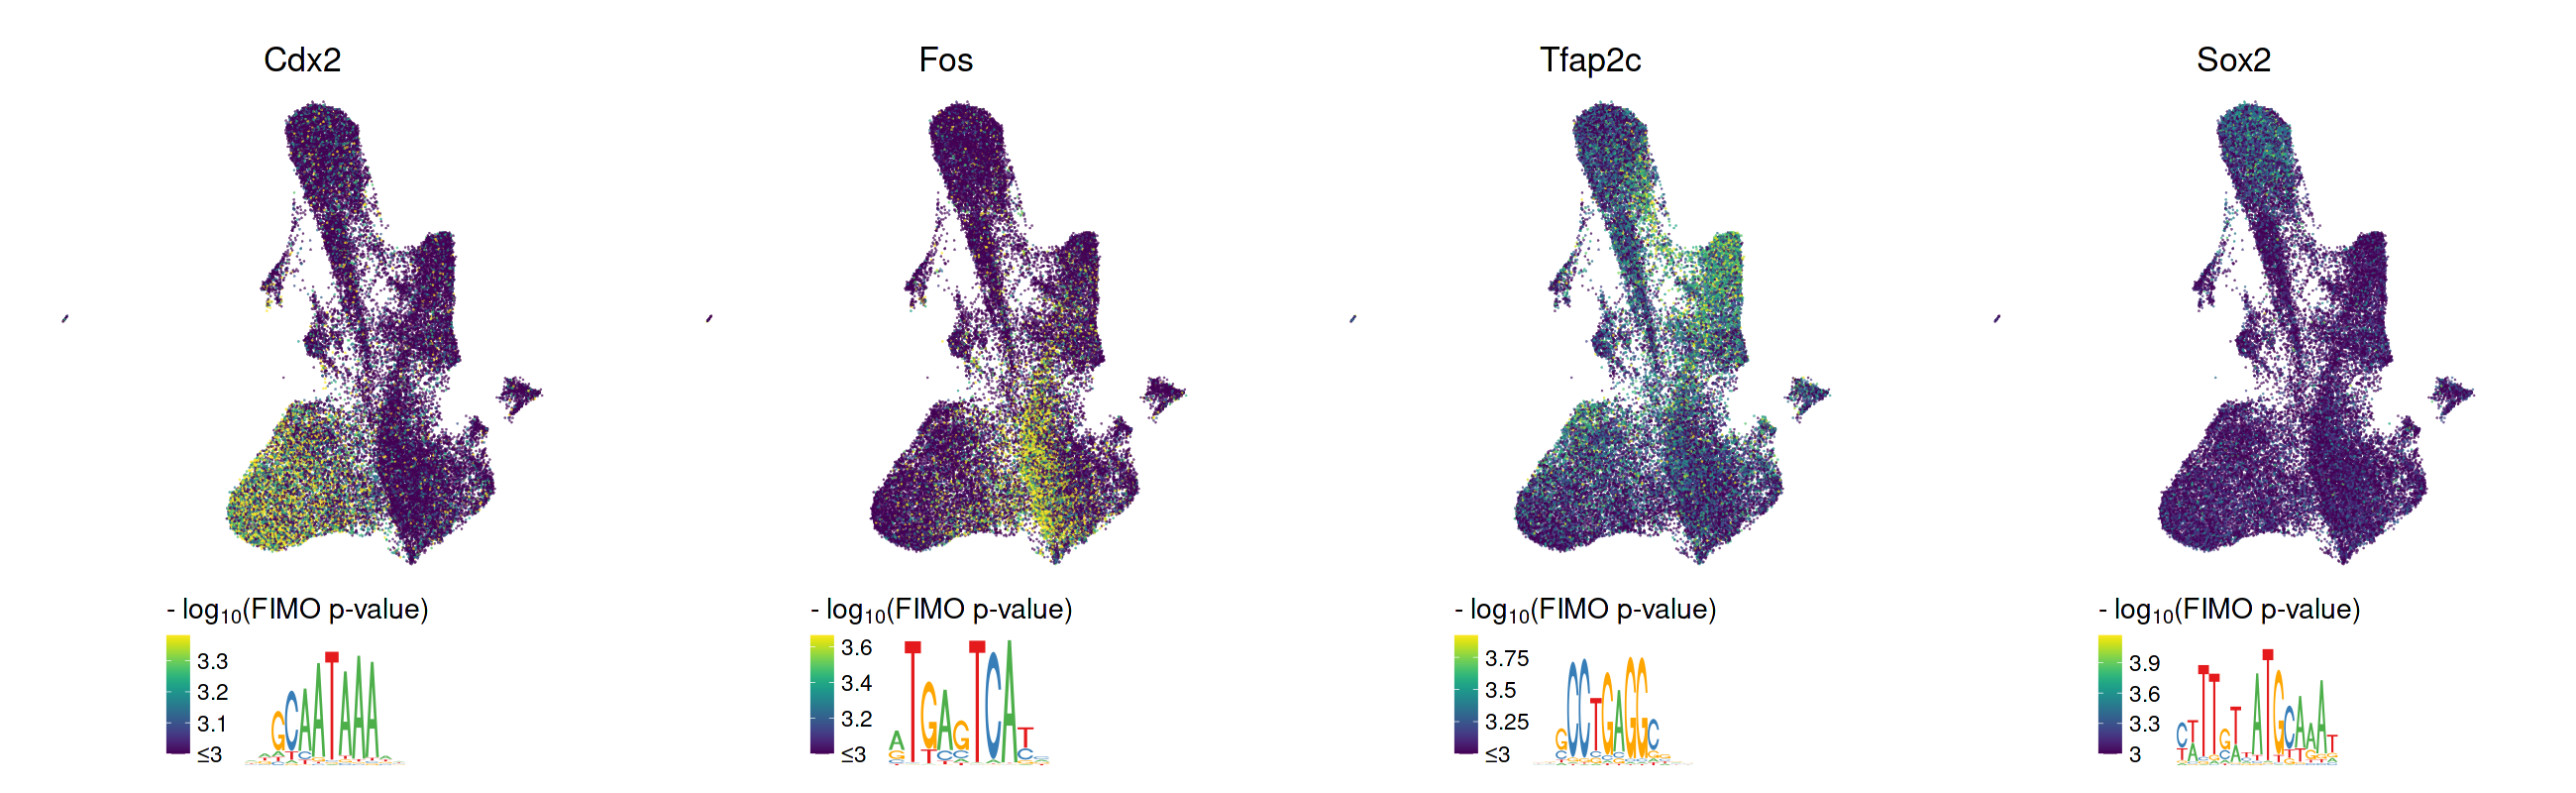

In [38]:
cdx2 <- motif_peak_UMAP("Cdx2", 1, .001)

fos <- motif_peak_UMAP("Fos", 1, .001)

tfap <- motif_peak_UMAP("Tfap2c", 2, .001)

sox2 <- motif_peak_UMAP("Sox2", 1, .001)

options(repr.plot.width=26, repr.plot.height=8, repr.plot.res=100)
ggarrange(cdx2,fos,tfap,sox2,ncol=4,nrow=1)

### DG site classification
Binning DG sites into groups based on their specificity for one (or more) TFs and visualizing in UMAP of peaks

In [39]:
## Inputs
tf_single <- c("Cdx2","Neurod1","Pax3","Sox7","Sox10")   # Sox5 handled separately
tf_sox5   <- c("Sox5","Nrf1")                            # Sox5 module
tf_ap2    <- c("Elf5","Grhl1","Gata1","Gata5","Gata6","Ovol1")

## 0) DG/DL site sets
DG_sites <- unique(all.sites[all.sites$significance == "DA", "site"])

DL_sites <- unique(all.sites[all.sites$significance == "DL", "site"])
DL_sites <- setdiff(DL_sites, DG_sites)  # DL-only, never DG anywhere

## 1) Map each DG site -> set of TFs for which it is DG
dg_df <- all.sites[all.sites$significance == "DA", c("site","target")]
dg_tfs_by_site <- split(dg_df$target, dg_df$site)
dg_tfs_by_site <- lapply(dg_tfs_by_site, unique)

dg_set <- function(site) dg_tfs_by_site[[site]]

## 2) Initialize labels for DG ∪ DL-only
all_interest_sites <- union(DG_sites, DL_sites)
site_group <- setNames(rep(NA_character_, length(all_interest_sites)), all_interest_sites)

## 3a) Assign Sox5 module:
## any site DG for Sox5 OR Nrf1, and DG for NO TF outside {Sox5, Nrf1}
sox5_module_sites <- DG_sites[sapply(DG_sites, function(s) {
  tfs <- sort(dg_set(s))
  any(tfs %in% tf_sox5) && all(tfs %in% tf_sox5)
})]
site_group[sox5_module_sites] <- "Sox5"

## 3b) Assign the remaining single-TF groups (Cdx2/Neurod1/Pax3/Sox7/Sox10):
## DG for exactly one TF and that TF is in tf_single
single_unique_sites <- DG_sites[sapply(DG_sites, function(s) {
  tfs <- dg_set(s)
  length(tfs) == 1 && tfs %in% tf_single
})]

# Do not overwrite Sox5 module sites
single_unique_sites <- setdiff(single_unique_sites, names(site_group)[!is.na(site_group)])
site_group[single_unique_sites] <- sapply(single_unique_sites, function(s) dg_set(s)[[1]])

## 4) Assign AP-2: DG for >=1 TF in tf_ap2 and DG for NO TF outside tf_ap2
ap2_sites <- DG_sites[sapply(DG_sites, function(s) {
  tfs <- dg_set(s)
  any(tfs %in% tf_ap2) && all(tfs %in% tf_ap2)
})]

# Do not overwrite already-assigned groups
ap2_sites <- setdiff(ap2_sites, names(site_group)[!is.na(site_group)])
site_group[ap2_sites] <- "AP-2"

## 5) Assign pluripotency = DL-only
site_group[DL_sites] <- "pluripotency"

## 6) Assign AP-1 = remaining DG sites not yet assigned
remaining_dg <- DG_sites[is.na(site_group[DG_sites])]
site_group[remaining_dg] <- "AP-1"

## Optional sanity checks
table(site_group, useNA = "ifany")
stopifnot(all(!is.na(site_group[all_interest_sites])))
stopifnot(all(site_group[DL_sites] == "pluripotency"))

## Example usage with UMAP.df where rownames are sites:
UMAP.df$group <- site_group[rownames(UMAP.df)]
UMAP.df$group[is.na(UMAP.df$group)] <- "other"

site_group
        AP-1         AP-2         Cdx2      Neurod1         Pax3 pluripotency 
        9566         2490        11765          325          140        10809 
       Sox10         Sox5         Sox7 
         767         2682          529 

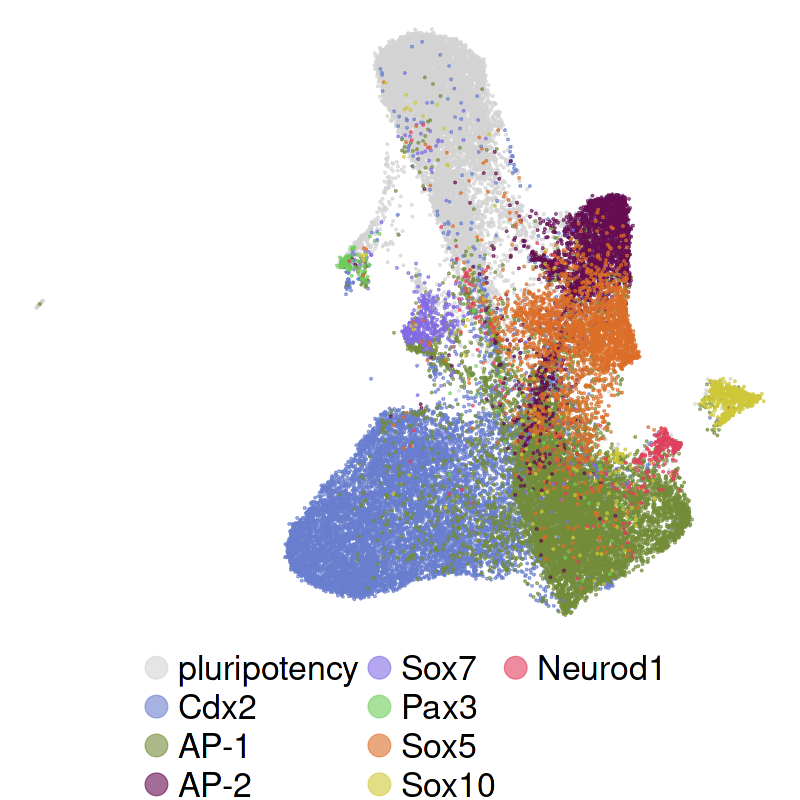

In [40]:
# Define plotting order
custom_order <- c(
  'pluripotency', 'Cdx2','AP-1','AP-2',
   'Sox7', 'Pax3', 'Sox5','Sox10', 'Neurod1'
)

UMAP.df$group <- factor(
  UMAP.df$group,
  levels = custom_order
)

# Sort rows by factor order (first rows are plotted first)
UMAP.df <- UMAP.df[order(UMAP.df$group), ]

options(repr.plot.width=8, repr.plot.height=8, repr.plot.res=100)
p <- ggplot() + geom_point_rast(data=UMAP.df,
                      aes(x=UMAP1,UMAP2,color=group),size=.5,alpha=.6) + 

      theme_void() +
      theme(text = element_text(size = 30),
            plot.title = element_text(hjust = 0.5)) + 
      guides(colour=guide_legend(nrow=4,override.aes = list(size=7))) + 
      theme(legend.position="bottom") +  labs(color="") + 
      scale_color_manual(
  values = c(
    "pluripotency" = "lightgrey",
    "AP-1"         = "#738C3A",
    "AP-2"         = "#660d53",
    "Cdx2"         = "#6a7fce",
    "Sox7"         = "#826be5",
    "Neurod1"      = "#e33f5d",
    "Sox10"        = "#cec83a",
    "Pax3"         = "#6fcd59",
    "Sox5"         = "#dc6e29"
  )
)

p

In [41]:
sessionInfo()

R version 4.3.2 (2023-10-31)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 22.04.5 LTS

Matrix products: default
BLAS:   /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRblas.so 
LAPACK: /net/gs/vol3/software/modules-sw/R/4.3.2/Linux/Ubuntu22.04/x86_64/lib/R/lib/libRlapack.so;  LAPACK version 3.11.0

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

time zone: America/Los_Angeles
tzcode source: system (glibc)

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] monocle3_1.3.5                     SingleCellExperiment_1.24.0       
 [3] leiden_0.4.3.1                     cowplot_1.2.0         